# Baseline Approach

The overall goal of this notebook is to establish a baseline benchmark for evaluating future models that will proposed. Since the goal is to estimate a value that doesn't have a comparable benchmark it is necessary to have some sort of framework / benchmark to measure against.

For simplicity this model will use the last observation of the quarter for prediction, and the analysis is restricted only to financial variables that are subject to a lag. Variables that combine accounting information with contemporaneously observed market data are excluded such as P/E ratio. The results will also be using only SPX, Russell, and NASDAQ for now. 

There are two schools of thought regarding this solution and there isn't a clear indication (theoritically) on which should perform better. 
1. Predicting quarter end values and then discounting them to current values
2. Predicting current values via nowcasted

# Pacakages & Global Variables

In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

import matplotlib.pyplot as plt
from   matplotlib.ticker import FuncFormatter

In [2]:
from tqdm import tqdm
tqdm.pandas()

In [3]:
note_path  = os.getcwd()
repo_path  = os.path.abspath(os.path.join(note_path, ".."))
src_path   = os.path.join(repo_path, "src")
data_path  = os.path.join(repo_path, "data")
db_path    = os.path.join(data_path, "DataBase")
daily_path = os.path.join(db_path, "DailyData")
quart_path = os.path.join(db_path, "Quarterlyized")
base_path  = os.path.join(data_path, "Models", "BaselineModels")

In [4]:
sample_tickers = ['SPX Index', 'RTY Index', 'NDX Index']

In [5]:
import sys
sys.path.append(src_path)
from OLSModels import OLSModels

In [6]:
add_dict = {
    "lag_vol_rtn": "Lagged",
    "rtn"        : "None",
    "vol_rtn"    : "Perfect"}

In [7]:
ticker_path = os.path.join(data_path, "EquityForecastTickerGuide.xlsx")
df_renamer  = pd.read_excel(io = ticker_path, sheet_name = "Renamer")

raw_renamer = (df_renamer
    .set_index("old_name")
    .loc[lambda x: x.group == "renamer"]
    .new_name
    .to_dict())

model_renamer = {
    "single": "Single",
    "multi" : "Multi"}

RENAMER = {**add_dict, **raw_renamer, **model_renamer}

plot_renamer = (df_renamer
    .set_index("old_name")
    .loc[lambda x: x.group == "plot_renamer"]
    .assign(name = lambda x: x.new_name.str.replace(r"\\n", "\n", regex = True))
    .name
    .to_dict())

model_plot_renamer = {
    "Single": "Single Lagged Parameter",
    "Multi" : "Multi Lagged Parameter"}

PLOT_RENAMER = {**plot_renamer, **model_plot_renamer}

FLOAT_FORMAT = "{:.2f}".format

In [8]:
sample_tickers = ['SPX Index', 'RTY Index', 'NDX Index']
stat_method    = ["last"]

# 1. Naive Quarter End Prediction

With this model we've taken the differences QoQ and then run a generic regression of the lagged values against themselves. We've also run a second regression that uses all of the available variables lagged a regression. This gives us the idea of the quality of the prediction before trying any new methodology. 

In [9]:
path = os.path.join(base_path, "SingleVarPredictiveModels.pkl")
with open(path, "rb") as f: models = pickle.load(f)
df_single_params = OLSModels().get_model_params(models)

In [10]:
path = os.path.join(base_path, "MultiVarPredictiveModels.pkl")
with open(path, "rb") as f: models = pickle.load(f)
df_multi_params = OLSModels().get_model_params(models)

In [11]:
df_single_r2 = (df_single_params
    [["adj_r2", "name"]]
    .drop_duplicates()
    .assign(
        model = "single",
        ticker = lambda x: x.name.str.split("-").str[0],
        field  = lambda x: x.name.str.split("-").str[1]))

df_multi_r2 = (df_multi_params
    [["adj_r2", "name"]]
    .drop_duplicates()
    .assign(
        model  = "multi",
        ticker = lambda x: x.name.str.split("-").str[0],
        field  = lambda x: x.name.str.split("-").str[1]))

df_r2 = (pd.concat([df_single_r2, df_multi_r2]))

Below is a plot of the $R^2$ of the naive regressions the idea is to get a baseline for the kinds of results we need to benchmark to

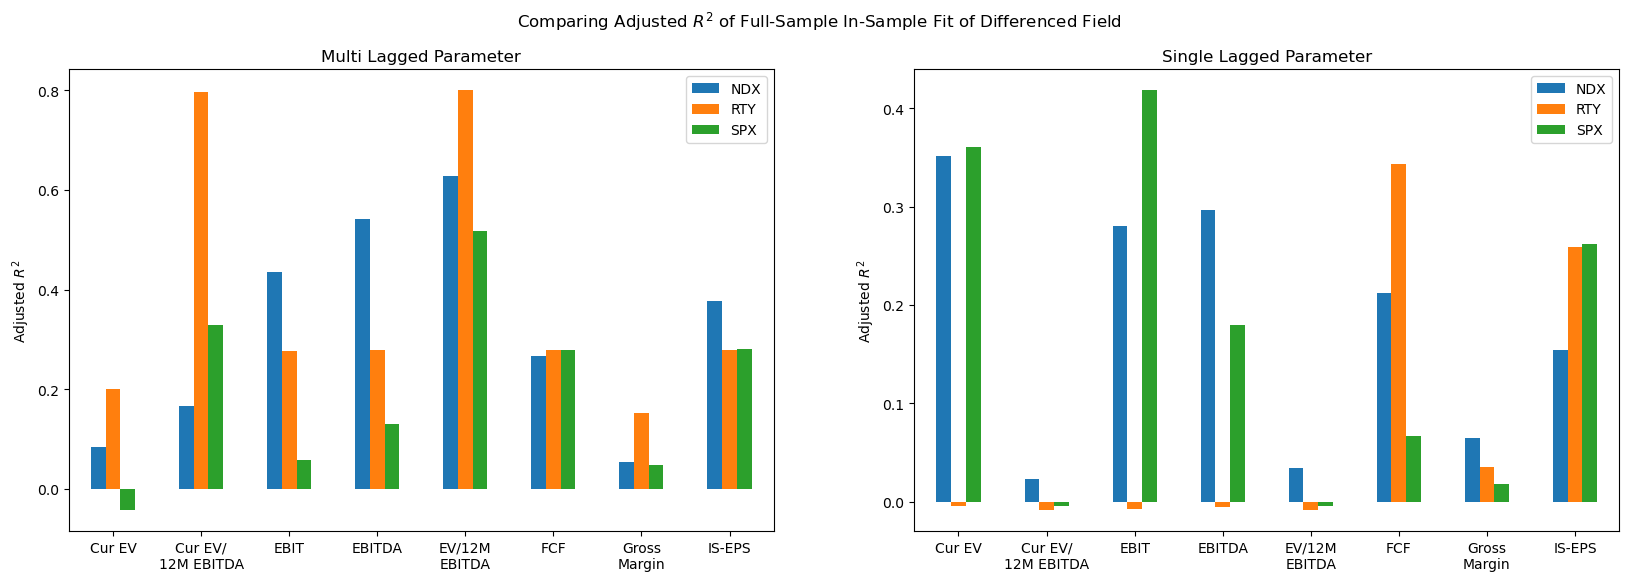

In [12]:
models    = df_r2.model.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = len(models), figsize = (20,6))

for model, ax in zip(models, axes.flatten()): 

    (df_r2
        .loc[lambda x: x.model == model]
        .replace(RENAMER)
        .replace(PLOT_RENAMER)
        .rename(columns = {"ticker": ""})
        .pivot(index = "field", columns = "", values = "adj_r2")
        .plot(
            title  = PLOT_RENAMER[RENAMER[model]],
            kind   = "bar",
            ax     = ax,
            rot    = 0,
            xlabel = "",
            ylabel = "Adjusted $R^2$"))

fig.suptitle("Comparing Adjusted $R^2$ of Full-Sample In-Sample Fit of Differenced Field")
plt.show()

# 2. Examining Factor Exposure

Now when we make a factor we want to measure its factor exposure to daily returns, in this case we'll use the forecasted values and run a regression comparing them. 

In [13]:
path          = os.path.join(data_path, "EquityForecastTickerGuide.xlsx")
df_ticker_map = (pd
    .read_excel(io = path, sheet_name = "FactorGuide")
    .loc[lambda x: x.est_field != "BEST_PE_RATIO"])

est_fields = df_ticker_map.est_field.drop_duplicates().sort_values().to_list()

In [14]:
path   = os.path.join(daily_path, "DailyEstimateEquityIndexData.parquet")
df_est = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.ticker.isin(sample_tickers)]
    .loc[lambda x: x.field.isin(est_fields)])

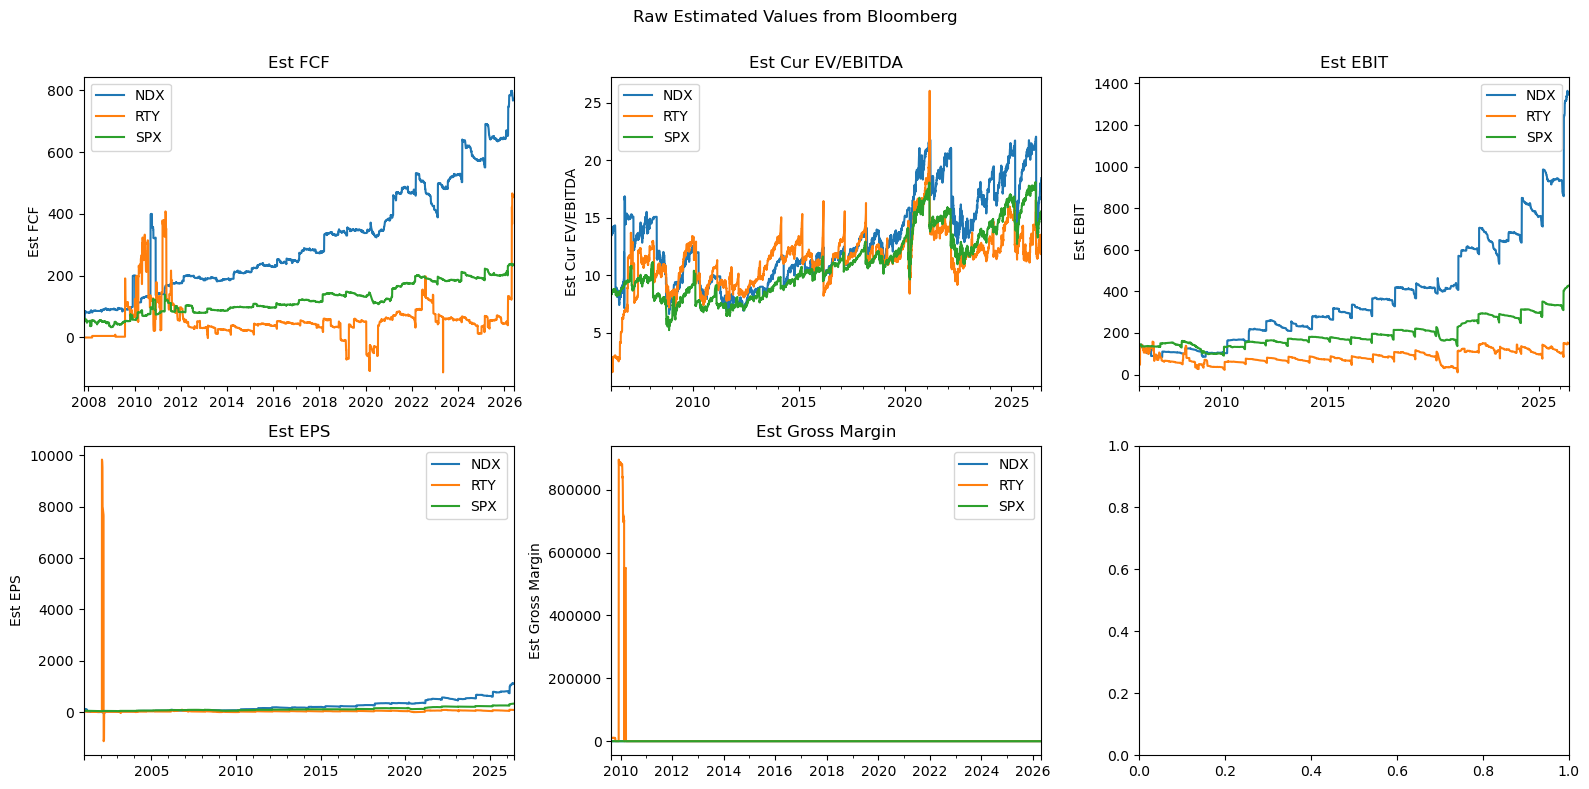

In [15]:
fields    = df_est.field.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = 3, nrows = 2, figsize = (16,8))

for field, ax in zip(fields, axes.flatten()): 

    df_tmp = (df_est
        .loc[lambda x: x.field == field]
        .assign(ticker = lambda x: x.ticker.str.split(" ").str[0])
        .drop(columns = ["field"])
        .drop_duplicates()
        .groupby(["date", "ticker"])
        .agg("min")
        .reset_index())

    (df_tmp
        .rename(columns = {"ticker": ""})
        .pivot(index = "date", columns = "", values = "value")
        .dropna()
        .plot(
            ax     = ax,
            ylabel = RENAMER[field],
            title  = RENAMER[field],
            xlabel = ""))

fig.suptitle("Raw Estimated Values from Bloomberg\n")
plt.tight_layout()

The values are quiet messy and in this case since we are measuring factor exposure of the detrended stationary variables we can apply a simple manipulation to make the differences easier to work with

In [16]:
path = r"A:\GitHub\CurrentFundamentalFactorModels\data\DataBase\PrepData\AdjAnalystEstimate.parquet"
df_adj_est = (pd
    .read_parquet(path = path, engine = "pyarrow")
    .loc[lambda x: x.field_type == "adj_val"])

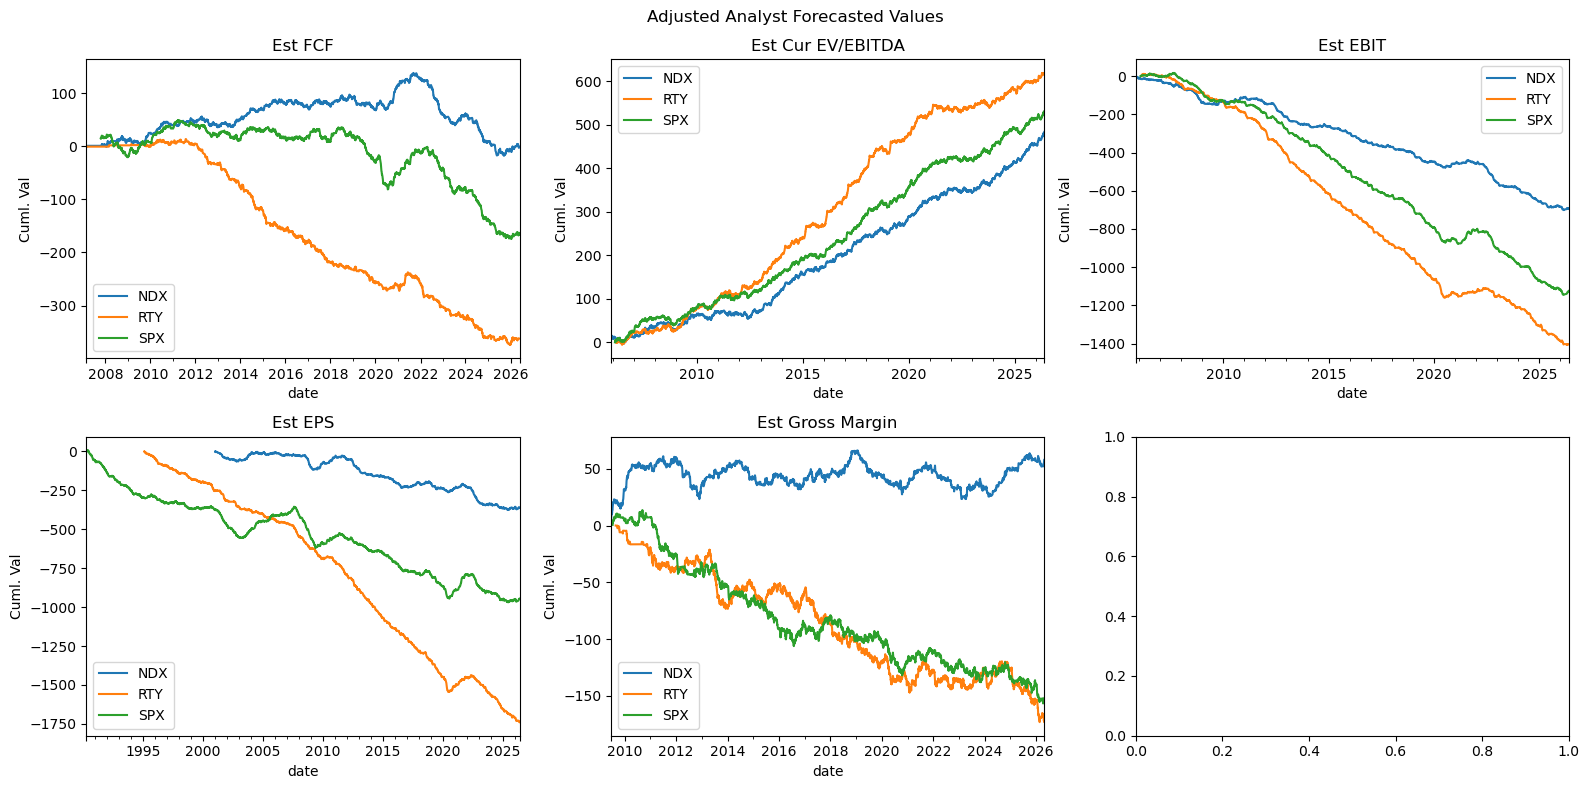

In [17]:
fields    = df_adj_est.field.drop_duplicates().sort_values().to_list()
fig, axes = plt.subplots(ncols = 3, nrows = 2, figsize = (16,8))

for field, ax in zip(fields, axes.flatten()): 

    (df_adj_est
        .loc[lambda x: x.field == field]
        .assign(ticker = lambda x: x.ticker.str.split(" ").str[0])
        .rename(columns = {"ticker": ""})
        .pivot(index = "date", columns = "", values = "value")
        .cumsum()
        .plot(
            ax     = ax,
            title  = RENAMER[field],
            ylabel = "Cuml. Val"))

fig.suptitle("Adjusted Analyst Forecasted Values")
plt.tight_layout()
plt.show()

The values are much cleaner to work with and they can be passed through a regression. 

In [18]:
path = r"A:\GitHub\CurrentFundamentalFactorModels\data\Models\BaselineModels\EstimatedFactorExposure.pkl"
with open(path, "rb") as f: models = pickle.load(f)
df_analyst_est = OLSModels().get_model_params(models)

In [19]:
(df_analyst_est
    .loc[lambda x: x.param_name == "value"]
    .drop(columns = ["param_name", "adj_r2", "r2"])
    .melt(id_vars = ["name"])
    .assign(
        str_split = lambda x: x.name.str.split("-"),
        ticker    = lambda x: x.str_split.str[0].str.split(" ").str[0],
        rtn_type  = lambda x: x.str_split.str[1],
        field     = lambda x: x.str_split.str[2].map(RENAMER))
    .replace(RENAMER)
    .rename(columns = {
        "rtn_type": "Vol Target",
        "field"   : "Field",
        "ticker"  : "Ticker",
        "variable": ""})
    .pivot(index = ["Ticker", "Field"], columns = ["", "Vol Target"], values = "value"))

param_val                  pvalue                \
Vol Target                    None   Perfect          None       Perfect   
Ticker Field                                                               
NDX    Est Cur EV/EBITDA  0.010048  0.004869  0.000000e+00  0.000000e+00   
       Est EBIT           0.000133  0.000021  5.997491e-01  8.482211e-01   
       Est EPS            0.000687  0.000185  6.309854e-03  5.853955e-02   
       Est FCF            0.000045  0.000104  8.618783e-01  3.607030e-01   
       Est Gross Margin  -0.000629 -0.000332  2.089287e-02  9.556683e-03   
RTY    Est Cur EV/EBITDA  0.010852  0.004687  0.000000e+00  0.000000e+00   
       Est EBIT          -0.000334 -0.000207  1.899158e-01  3.977882e-02   
       Est EPS            0.000665  0.000274  6.477871e-04  1.140734e-03   
       Est FCF           -0.000324 -0.000122  2.957086e-01  3.140577e-01   
       Est Gross Margin  -0.001748 -0.000993  3.170132e-12  3.181817e-20   
SPX    Est Cur EV/EBITDA  0.009100  0.005240  0.000000e+00  0.000000e+00   
       Est EBIT           0.000033  0.000043  8.649295e-01  6.623339e-01   
       Est EPS            0.000870  0.000454  9.128511e-11  4.751958e-10   
       Est FCF            0.000077  0.000035  7.130006e-01  7.341744e-01   
       Est Gross Margin   0.000735  0.000236  2.087525e-04  3.410484e-02   

                             tvalue             
Vol Target                     None    Perfect  
Ticker Field                                    
NDX    Est Cur EV/EBITDA  58.734732  69.476788  
       Est EBIT            0.524794   0.191398  
       Est EPS             2.732134   1.891975  
       Est FCF             0.173993   0.914113  
       Est Gross Margin   -2.310779  -2.592650  
RTY    Est Cur EV/EBITDA  56.343475  65.544869  
       Est EBIT           -1.311003  -2.056565  
       Est EPS             3.412134   3.254488  
       Est FCF            -1.045793  -1.006849  
       Est Gross Margin   -6.990624  -9.260020  
SPX    Est Cur EV/EBITDA  65.231211  85.782176  
       Est EBIT            0.170111   0.436719  
       Est EPS             6.488384   6.233895  
       Est FCF             0.367851   0.339598  
       Est Gross Margin    3.711424   2.119519